# Scenario - 1 Only Past Power as input


A chronological D to D+1 solar power forecast using only past `Act. Power (MW)`. No weather, calendar, or future time features are used.

# 1. Project Configuration

Imports, paths, artifact locations, and configuration variables are defined in the next cell.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model

artifact_dir = Path(r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks")
model_path = artifact_dir / "scenario1_encoder_decoder.keras"
scaler_path = artifact_dir / "scenario1_scaler.joblib"
results_path = artifact_dir / "scenario1_test_results.npz"



# 2. Load Dataset

Load the existing chronological Excel datasets and inspect their row/day counts. No raw data or split files are changed.

In [6]:
from pathlib import Path
import pandas as pd

SEASON = "Summer"

DATA_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
    r"\OneDrive_2026-08-26\Solar Profile Dataset\Summer"
)

TRAIN_PATH = DATA_DIR / "Summer_Train.xlsx"
VALIDATION_PATH = DATA_DIR / "Summer_Val.xlsx"
TEST_PATH = DATA_DIR / "Summer_Test.xlsx"

TEST_START = pd.Timestamp("2026-06-08")
TEST_END_EXCLUSIVE = pd.Timestamp("2026-06-15")
HISTORY_DAY = TEST_START - pd.Timedelta(days=1)


def load_split(path):
    data = pd.read_excel(path)
    data["TimeStamp"] = pd.to_datetime(
        data["TimeStamp"], errors="raise"
    )

    if data["TimeStamp"].isna().any():
        raise ValueError(f"{path.name}: missing timestamps.")

    data = data.sort_values("TimeStamp").reset_index(drop=True)
    data["Date"] = data["TimeStamp"].dt.date
    return data


def check_split(data, name, first_day, last_day):
    expected = pd.date_range(
        start=first_day,
        end=pd.Timestamp(last_day) + pd.Timedelta(hours=23, minutes=45),
        freq="15min",
    )
    observed = pd.DatetimeIndex(data["TimeStamp"])

    if not observed.equals(expected):
        raise ValueError(
            f"{name}: expected a complete, unique 15-minute grid "
            f"from {first_day} through {last_day}. "
            f"Found {len(observed)} rows; expected {len(expected)}."
        )

    print(
        f"{name}: {data['Date'].nunique()} days | {len(data)} rows | "
        f"{observed[0]} → {observed[-1]}"
    )


# Load the existing files.
train = load_split(TRAIN_PATH)
validation = load_split(VALIDATION_PATH)
original_test = load_split(TEST_PATH)

# Validation already includes June 3–7.
check_split(train, "Training", "2026-02-15", "2026-05-09")
check_split(validation, "Validation", "2026-05-10", "2026-06-07")

# Retain exactly seven target days, even if the test file starts earlier.
test = original_test.loc[
    original_test["TimeStamp"].ge(TEST_START)
    & original_test["TimeStamp"].lt(TEST_END_EXCLUSIVE)
].copy().reset_index(drop=True)

check_split(test, "Test targets", "2026-06-08", "2026-06-14")

if set(validation.columns) != set(test.columns):
    raise ValueError("Validation and test column names differ.")

# June 7 supplies historical inputs for the June 8 forecast.
history_day = validation.loc[
    validation["Date"] == HISTORY_DAY.date()
].copy()

test_with_history = pd.concat(
    [history_day, test],
    ignore_index=True,
).sort_values("TimeStamp", ignore_index=True)

check_split(
    test_with_history,
    "Test including history",
    "2026-06-07",
    "2026-06-14",
)

print("\nTest target dates: June 8–14, 2026")
print("Expected test samples: 7 days × 4 revisions = 28")
print("Use test_with_history in the test sample-creation call.")

Training: 84 days | 8064 rows | 2026-02-15 00:00:00 → 2026-05-09 23:45:00
Validation: 29 days | 2784 rows | 2026-05-10 00:00:00 → 2026-06-07 23:45:00
Test targets: 7 days | 672 rows | 2026-06-08 00:00:00 → 2026-06-14 23:45:00
Test including history: 8 days | 768 rows | 2026-06-07 00:00:00 → 2026-06-14 23:45:00

Test target dates: June 8–14, 2026
Expected test samples: 7 days × 4 revisions = 28
Use test_with_history in the test sample-creation call.


# 3. Train / Validation / Test Split

The notebook uses the existing chronological Excel splits without re-splitting or shuffling the datasets.

# 4. Revision Sample Creation

Put the existing revision lengths, target length, padded input length, sample creator, and train/validation/test sample creation in this section.

In [7]:
import numpy as np
import pandas as pd

REVISION_LENGTHS = {
    "R0": 32,
    "R1": 50,
    "R2": 64,
    "R3": 82,
}

TARGET_LENGTH = 96
BLOCKS_PER_DAY = 96
PADDED_INPUT_LENGTH = max(REVISION_LENGTHS.values())
POWER_COLUMN = "Act. Power (MW)"


def create_revision_samples(split):
    """Create D → D+1 samples using past power only, before scaling/padding."""
    data = split.copy()
    data["TimeStamp"] = pd.to_datetime(data["TimeStamp"], errors="raise")
    data = data.sort_values("TimeStamp").reset_index(drop=True)
    data["Date"] = data["TimeStamp"].dt.date

    if data["TimeStamp"].isna().any():
        raise ValueError("Missing timestamps found.")

    if data["TimeStamp"].duplicated().any():
        raise ValueError("Duplicate timestamps found.")

    day_groups = {
        day: rows.set_index("TimeStamp")
        for day, rows in data.groupby("Date", sort=True)
    }

    X = []
    y = []
    revision_labels = []
    sample_dates = []
    revision_sample_indices = {
        revision: [] for revision in REVISION_LENGTHS
    }

    for day, day_data in day_groups.items():
        next_day = (pd.Timestamp(day) + pd.Timedelta(days=1)).date()
        next_day_data = day_groups.get(next_day)

        # The final day has no following target day in this dataframe.
        if next_day_data is None:
            continue

        history_grid = pd.date_range(
            start=pd.Timestamp(day),
            periods=PADDED_INPUT_LENGTH,
            freq="15min",
        )
        target_grid = pd.date_range(
            start=pd.Timestamp(next_day),
            periods=TARGET_LENGTH,
            freq="15min",
        )

        if not history_grid.isin(day_data.index).all():
            raise ValueError(f"{day}: missing required history blocks.")

        if not next_day_data.index.equals(target_grid):
            raise ValueError(f"{next_day}: incomplete target-day grid.")

        day_power = pd.to_numeric(
            day_data.loc[history_grid, POWER_COLUMN],
            errors="raise",
        ).to_numpy(dtype=np.float32)

        next_day_power = pd.to_numeric(
            next_day_data.loc[target_grid, POWER_COLUMN],
            errors="raise",
        ).to_numpy(dtype=np.float32)

        if (
            not np.isfinite(day_power).all()
            or not np.isfinite(next_day_power).all()
        ):
            raise ValueError(
                f"{day} → {next_day}: missing or infinite power values."
            )

        for revision, sequence_length in REVISION_LENGTHS.items():
            sample_index = len(X)

            X.append(day_power[:sequence_length, np.newaxis].copy())
            y.append(next_day_power.copy())
            revision_labels.append(revision)
            sample_dates.append(next_day)
            revision_sample_indices[revision].append(sample_index)

    if not X:
        raise ValueError("No valid D → D+1 samples found.")

    return (
        X,
        np.stack(y).astype(np.float32),
        np.asarray(revision_labels),
        revision_sample_indices,
        np.asarray(sample_dates),
    )


# Training and validation use their own historical days.
(
    X_train,
    y_train,
    revision_labels_train,
    revision_indices_train,
    dates_train,
) = create_revision_samples(train)

(
    X_validation,
    y_validation,
    revision_labels_validation,
    revision_indices_validation,
    dates_validation,
) = create_revision_samples(validation)

# June 7 is history; June 8–14 are the seven forecast target days.
(
    X_test,
    y_test,
    revision_labels_test,
    revision_indices_test,
    dates_test,
) = create_revision_samples(test_with_history)


revision_info = {
    "lengths": REVISION_LENGTHS.copy(),
    "train": revision_indices_train,
    "validation": revision_indices_validation,
    "test": revision_indices_test,
}


# Require exactly one sample for every summer test date and revision.
expected_dates = pd.date_range(
    "2026-06-08", "2026-06-14", freq="D"
).date

expected_pairs = {
    (date, revision)
    for date in expected_dates
    for revision in REVISION_LENGTHS
}
actual_pairs = set(zip(dates_test, revision_labels_test))

if (
    actual_pairs != expected_pairs
    or len(dates_test) != len(expected_pairs)
    or y_test.shape != (28, TARGET_LENGTH)
):
    raise ValueError(
        "Expected 28 test samples: June 8–14, 2026, "
        "with four revisions and 96 target blocks per day."
    )

# Target dates must remain separate across splits.
target_sets = [
    set(dates_train),
    set(dates_validation),
    set(dates_test),
]
if any(
    target_sets[i] & target_sets[j]
    for i, j in ((0, 1), (0, 2), (1, 2))
):
    raise ValueError("Target dates overlap across splits.")


print("Split       | Samples | Target shape")
for split_name, targets in (
    ("Train", y_train),
    ("Validation", y_validation),
    ("Test", y_test),
):
    print(f"{split_name:<11} | {len(targets):>7} | {targets.shape}")

print("\nTest samples per target date and revision:")
print(pd.crosstab(
    pd.Series(dates_test, name="Target date"),
    pd.Series(revision_labels_test, name="Revision"),
))

Split       | Samples | Target shape
Train       |     332 | (332, 96)
Validation  |     112 | (112, 96)
Test        |      28 | (28, 96)

Test samples per target date and revision:
Revision     R0  R1  R2  R3
Target date                
2026-06-08    1   1   1   1
2026-06-09    1   1   1   1
2026-06-10    1   1   1   1
2026-06-11    1   1   1   1
2026-06-12    1   1   1   1
2026-06-13    1   1   1   1
2026-06-14    1   1   1   1


In [8]:
from sklearn.preprocessing import MinMaxScaler
# Fit only on real training power values from the raw training dataframe.
scaler = MinMaxScaler()
scaler.fit(train[[POWER_COLUMN]].to_numpy())

train_power_scaled = scaler.transform(train[[POWER_COLUMN]].to_numpy())
val_power_scaled = scaler.transform(validation[[POWER_COLUMN]].to_numpy())
test_power_scaled = scaler.transform(test[[POWER_COLUMN]].to_numpy())

# 5. Preprocessing and Scaling

This section preserves the existing `MinMaxScaler`, time features, padding, and scaled input creation.

In [10]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

PAD_VALUE = -1.0

# Fit only on summer training power.
training_power = train[[POWER_COLUMN]].to_numpy(dtype=np.float64)

if not np.isfinite(training_power).all():
    raise ValueError("Summer training power contains missing/infinite values.")

scaler = MinMaxScaler()
scaler.fit(training_power)


def time_features(block_indices):
    """Block 0 = 00:00; block 95 = 23:45."""
    block_indices = np.asarray(block_indices, dtype=np.float64)
    phase = 2.0 * np.pi * block_indices / BLOCKS_PER_DAY

    return np.column_stack(
        (np.sin(phase), np.cos(phase))
    ).astype(np.float32)


def preprocess_revision_samples(X_raw, y_raw, revision_labels, scaler):
    """Scale real power, add time features, then post-pad with -1."""
    labels = np.asarray(revision_labels)
    targets = np.asarray(y_raw, dtype=np.float32)

    if len(X_raw) != len(labels):
        raise ValueError("History and revision-label counts differ.")

    if targets.shape != (len(X_raw), TARGET_LENGTH):
        raise ValueError(f"Unexpected target shape: {targets.shape}")

    if not np.isfinite(targets).all():
        raise ValueError("Targets contain missing/infinite values.")

    X_processed = np.full(
        (len(X_raw), PADDED_INPUT_LENGTH, 3),
        PAD_VALUE,
        dtype=np.float32,
    )

    y_scaled = scaler.transform(
        targets.reshape(-1, 1)
    ).reshape(targets.shape).astype(np.float32)

    for index, (history, revision) in enumerate(zip(X_raw, labels)):
        if revision not in REVISION_LENGTHS:
            raise ValueError(f"Unknown revision: {revision}")

        real_length = REVISION_LENGTHS[revision]
        history = np.asarray(history, dtype=np.float32)

        if history.shape != (real_length, 1):
            raise ValueError(
                f"Sample {index}: expected {(real_length, 1)}, "
                f"received {history.shape}."
            )

        if not np.isfinite(history).all():
            raise ValueError(f"Sample {index}: nonfinite history values.")

        X_processed[index, :real_length, 0] = (
            scaler.transform(history).ravel()
        )
        X_processed[index, :real_length, 1:] = (
            time_features(np.arange(real_length))
        )

    return X_processed, y_scaled


X_train_scaled, y_train_scaled = preprocess_revision_samples(
    X_train, y_train, revision_labels_train, scaler
)

X_validation_scaled, y_validation_scaled = preprocess_revision_samples(
    X_validation, y_validation, revision_labels_validation, scaler
)

X_test_scaled, y_test_scaled = preprocess_revision_samples(
    X_test, y_test, revision_labels_test, scaler
)


# Summer target-day counts for within-split D → D+1 samples.
for name, X, y, labels, expected_days in (
    ("Train", X_train_scaled, y_train_scaled, revision_labels_train, 83),
    (
        "Validation",
        X_validation_scaled,
        y_validation_scaled,
        revision_labels_validation,
        28,
    ),
    ("Test", X_test_scaled, y_test_scaled, revision_labels_test, 7),
):
    expected_samples = expected_days * len(REVISION_LENGTHS)

    assert X.shape == (expected_samples, PADDED_INPUT_LENGTH, 3), (
        f"{name}: input shape"
    )
    assert y.shape == (expected_samples, TARGET_LENGTH), (
        f"{name}: target shape"
    )
    assert np.isfinite(X).all() and np.isfinite(y).all(), (
        f"{name}: missing or infinite values"
    )

    for revision, length in REVISION_LENGTHS.items():
        histories = X[labels == revision]

        assert len(histories) == expected_days, (
            f"{name} {revision}: sample count"
        )
        assert np.all(histories[:, length:, :] == PAD_VALUE), (
            f"{name} {revision}: padding"
        )
        assert not np.any(
            np.all(histories[:, :length, :] == PAD_VALUE, axis=-1)
        ), f"{name} {revision}: real timestep incorrectly masked"

        assert np.allclose(
            histories[:, :length, 1:],
            time_features(np.arange(length)),
            atol=1e-6,
            rtol=0.0,
        ), f"{name} {revision}: time features"

    print(
        f"{name}: {expected_days} target days | "
        f"X {X.shape} | y {y.shape}"
    )

Train: 83 target days | X (332, 82, 3) | y (332, 96)
Validation: 28 target days | X (112, 82, 3) | y (112, 96)
Test: 7 target days | X (28, 82, 3) | y (28, 96)


# 6. Reproducibility

This section must run before model creation or training.

In [11]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

Reproducibility configured with seed 42.


# 7. Model Architecture

This section contains only the existing encoder-decoder model definition.

In [12]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping

# Scenario 1 configuration
SEED = 42
MASK_VALUE = -1.0
N_HISTORY_FEATURES = X_train_scaled.shape[-1]
N_FUTURE_EXOG = 0

assert N_HISTORY_FEATURES == 3, "Scenario 1 expects past power, time sine, and time cosine."


def build_model(n_future_exog):
    """Build the shared RNN architecture for the selected input features."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name='encoder_input',
    )
    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name='encoder_masking',
    )(encoder_input)
    encoder_context = SimpleRNN(
        64,
        name='encoder_rnn',
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name='future_input',
    )
    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name='repeat_context',
    )(encoder_context)
    decoder_input = Concatenate(
        axis=-1,
        name='decoder_features',
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name='decoder_rnn',
    )(decoder_input)
    block_predictions = TimeDistributed(
        Dense(1),
        name='block_prediction',
    )(decoder_sequence)
    forecast = Reshape(
        (TARGET_LENGTH,),
        name='forecast',
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )
    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae'],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


# Build a fresh Scenario 1 model for training.
model = build_model(N_FUTURE_EXOG)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 82, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 82, 3)     │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_masking     │ (None, 82, 3)     │          0 │ encoder_input[0]… │
│ (Masking)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 82)        │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_rnn         │ (None, 64)        │      4,352 │ encoder_masking[… │
│ (SimpleRNN)         │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 96, 64)    │          0 │ encoder_rnn[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_input        │ (None, 96, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_features    │ (None, 96, 66)    │          0 │ repeat_context[0… │
│ (Concatenate)       │                   │            │ future_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_rnn         │ (None, 96, 64)    │      8,384 │ decoder_features… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_prediction    │ (None, 96, 1)     │         65 │ decoder_rnn[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast (Reshape)  │ (None, 96)        │          0 │ block_prediction… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,801 (50.00 KB)

 Trainable params: 12,801 (50.00 KB)

 Non-trainable params: 0 (0.00 B)

Computation timing calculation

In [9]:
from time import perf_counter
import tensorflow as tf


class ComputationTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.fit_start = perf_counter()
        self.validation_seconds = 0.0
        self.epochs_completed = 0

    def on_test_begin(self, logs=None):
        # Keras calls this for validation inside model.fit().
        self.validation_start = perf_counter()

    def on_test_end(self, logs=None):
        self.validation_seconds += perf_counter() - self.validation_start

    def on_epoch_end(self, epoch, logs=None):
        self.epochs_completed += 1

    def on_train_end(self, logs=None):
        self.fit_seconds = perf_counter() - self.fit_start

# 8. Model Training

**RUN ONLY WHEN TRAINING THE MODEL**  
**DO NOT RUN FOR DEMO**

In [13]:
from pathlib import Path
from time import perf_counter
from datetime import datetime
import platform

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping


# 1. Summer benchmark settings
SEASON = "Summer"
SCENARIO = "S1"
BATCH_SIZE = 16
MAX_EPOCHS = 150

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
timing_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Timing"
)
timing_dir.mkdir(parents=True, exist_ok=True)


# 2. Prepare next-day clock inputs.
future_time = time_features(np.arange(TARGET_LENGTH))

def make_future_time_inputs(n_samples):
    return np.repeat(
        future_time[None, :, :], n_samples, axis=0
    ).astype(np.float32)

future_time_train = make_future_time_inputs(len(X_train_scaled))
future_time_validation = make_future_time_inputs(
    len(X_validation_scaled)
)
future_time_test = make_future_time_inputs(len(X_test_scaled))

for name, X, clock, y, expected_samples in (
    (
        "Train",
        X_train_scaled,
        future_time_train,
        y_train_scaled,
        332,
    ),
    (
        "Validation",
        X_validation_scaled,
        future_time_validation,
        y_validation_scaled,
        112,
    ),
    (
        "Test",
        X_test_scaled,
        future_time_test,
        y_test_scaled,
        28,
    ),
):
    if X.shape != (expected_samples, PADDED_INPUT_LENGTH, 3):
        raise ValueError(f"{name}: unexpected history shape {X.shape}")

    if clock.shape != (expected_samples, TARGET_LENGTH, 2):
        raise ValueError(f"{name}: unexpected clock-input shape.")

    if y.shape != (expected_samples, TARGET_LENGTH):
        raise ValueError(f"{name}: unexpected target shape {y.shape}")

    if not all(np.isfinite(array).all() for array in (X, clock, y)):
        raise ValueError(f"{name}: missing or infinite values.")


# Uses the existing S1 builder with fresh weights and its configured seed.
benchmark_model = build_model(n_future_exog=0)

if benchmark_model.input_shape != [
    (None, PADDED_INPUT_LENGTH, 3),
    (None, TARGET_LENGTH, 2),
]:
    raise ValueError("The model builder is not configured for Scenario 1.")


# 3. Measure validation passes inside fit().
class ValidationTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.validation_seconds = 0.0
        self.validation_passes = 0

    def on_test_begin(self, logs=None):
        self.validation_start = perf_counter()

    def on_test_end(self, logs=None):
        self.validation_seconds += (
            perf_counter() - self.validation_start
        )
        self.validation_passes += 1


timer = ValidationTimer()

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=15,
    restore_best_weights=True,
)


# 4. Time training and internal validation.
fit_start = perf_counter()

benchmark_history = benchmark_model.fit(
    [X_train_scaled, future_time_train],
    y_train_scaled,
    validation_data=(
        [X_validation_scaled, future_time_validation],
        y_validation_scaled,
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=False,
    callbacks=[early_stopping, timer],
    verbose=1,
)

fit_seconds = perf_counter() - fit_start
validation_seconds = timer.validation_seconds

# Training includes remaining fit/callback overhead.
training_seconds = fit_seconds - validation_seconds

validation_losses = np.asarray(
    benchmark_history.history["val_loss"], dtype=np.float64
)
if (
    validation_losses.size == 0
    or not np.isfinite(validation_losses).all()
):
    raise ValueError("Invalid benchmark validation losses.")


# 5. Time the first prediction call over all seven test days.
test_start = perf_counter()

benchmark_predictions_scaled = benchmark_model.predict(
    [X_test_scaled, future_time_test],
    batch_size=BATCH_SIZE,
    verbose=0,
)

testing_seconds = perf_counter() - test_start
overall_seconds = fit_seconds + testing_seconds

if benchmark_predictions_scaled.shape != (28, TARGET_LENGTH):
    raise ValueError("Unexpected benchmark prediction shape.")

if not np.isfinite(benchmark_predictions_scaled).all():
    raise ValueError("Benchmark predictions contain nonfinite values.")


# 6. Save timing records.
run_id = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
gpu_devices = tf.config.list_physical_devices("GPU")

record = {
    "Model": "RNN",
    "Season": SEASON,
    "Scenario": SCENARIO,
    "Run_ID": run_id,
    "Run_Type": "Repeated training benchmark",
    "Epochs": len(benchmark_history.history["loss"]),
    "Best_Epoch": int(np.argmin(validation_losses)) + 1,
    "Batch_Size": BATCH_SIZE,
    "Training_s": training_seconds,
    "Validation_s": validation_seconds,
    "Testing_s": testing_seconds,
    "Overall_s": overall_seconds,
    "Validation_Passes": timer.validation_passes,
    "Train_Samples": len(X_train_scaled),
    "Validation_Samples": len(X_validation_scaled),
    "Test_Samples": len(X_test_scaled),
    "CPU": platform.processor(),
    "Visible_GPUs": "; ".join(
        tf.config.experimental.get_device_details(device).get(
            "device_name", device.name
        )
        for device in gpu_devices
    ) or "None",
    "TensorFlow_Version": tf.__version__,
    "OS": platform.platform(),
}

timing_row = pd.DataFrame([record])

run_path = timing_dir / (
    f"{SEASON}_RNN_{SCENARIO}_Timing_{run_id}.csv"
)
timing_row.to_csv(run_path, index=False)

history_path = timing_dir / (
    f"{SEASON}_RNN_{SCENARIO}_History_{run_id}.csv"
)
pd.DataFrame(benchmark_history.history).to_csv(
    history_path, index=False
)

summary_path = timing_dir / f"{SEASON}_RNN_Computation_Times.csv"

if summary_path.exists():
    timing_summary = pd.concat(
        [pd.read_csv(summary_path), timing_row],
        ignore_index=True,
    )
else:
    timing_summary = timing_row.copy()

timing_summary = (
    timing_summary
    .drop_duplicates(
        subset=["Model", "Season", "Scenario"],
        keep="last",
    )
    .sort_values(
        ["Model", "Season", "Scenario"],
        ignore_index=True,
    )
)
timing_summary.to_csv(summary_path, index=False)

print(f"\n{SEASON} — {SCENARIO}")
print(f"Epochs completed: {record['Epochs']}")
print(f"Best epoch:       {record['Best_Epoch']}")
print(f"Training time:    {training_seconds:.3f} seconds")
print(f"Validation time:  {validation_seconds:.3f} seconds")
print(f"Testing time:     {testing_seconds:.3f} seconds")
print(f"Overall time:     {overall_seconds:.3f} seconds")
print(f"\nTiming summary saved to: {summary_path}")

Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 14s 236ms/step - loss: 0.1354 - mae: 0.2761 - val_loss: 0.0263 - val_mae: 0.1356
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0313 - mae: 0.1468 - val_loss: 0.0204 - val_mae: 0.1210
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 0.0254 - mae: 0.1316 - val_loss: 0.0173 - val_mae: 0.1093
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0235 - mae: 0.1244 - val_loss: 0.0152 - val_mae: 0.1014
Epoch 5/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - loss: 0.0209 - mae: 0.1163 - val_loss: 0.0142 - val_mae: 0.0963
Epoch 6/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - loss: 0.0191 - mae: 0.1100 - val_loss: 0.0138 - val_mae: 0.0934
Epoch 7/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 0.0184 - mae: 0.1068 - val_loss: 0.0137 - val_mae: 0.0923
Epoch 8/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - loss: 0.0178 - mae: 0.1044 - val_loss: 0.0136 - val_mae: 0.0930
Epoch 9/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - 

# 9. Training Evaluation

Training-only loss visualization. **DO NOT RUN FOR DEMO.**

In [14]:
# TRAINING ONLY: requires history from the Model Training section.
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training and Validation Loss')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'history' is not defined

<Figure size 1000x500 with 0 Axes>

# 10. Test Prediction and Metrics

**RUN ONLY WHEN GENERATING NEW PREDICTIONS**  
This section preserves model prediction, inverse scaling, nighttime constraint, and overall/revision-wise MAE, RMSE, and R².

In [16]:
# Convert the summer benchmark predictions back to MW.
y_pred_raw = scaler.inverse_transform(
    benchmark_predictions_scaled.reshape(-1, 1)
).reshape(benchmark_predictions_scaled.shape)

y_actual = np.asarray(y_test, dtype=np.float64).copy()

if y_pred_raw.shape != y_actual.shape:
    raise ValueError("Prediction and target shapes do not match.")

if not np.isfinite(y_pred_raw).all():
    raise ValueError("Predictions contain missing or infinite values.")


# Derive the night mask from summer training data only.
complete_training_days = []

for day, rows in train.groupby("Date", sort=True):
    rows = rows.sort_values("TimeStamp")
    expected_times = pd.date_range(
        start=pd.Timestamp(day),
        periods=BLOCKS_PER_DAY,
        freq="15min",
    )

    if pd.DatetimeIndex(rows["TimeStamp"]).equals(expected_times):
        power = rows[POWER_COLUMN].to_numpy(dtype=np.float64)

        if not np.isfinite(power).all():
            raise ValueError(f"Invalid training power on {day}.")

        complete_training_days.append(power)

if not complete_training_days:
    raise ValueError("No complete training days found.")

active_fraction = np.mean(
    np.stack(complete_training_days) > 0.1,
    axis=0,
)
night_mask = active_fraction < 0.10
night_blocks = np.flatnonzero(night_mask)


# Final forecasts: nonnegative power and training-derived night mask.
y_pred = np.maximum(y_pred_raw, 0.0)
y_pred[:, night_mask] = 0.0

print(f"Summer S1 predictions ready: {y_pred.shape}")
print(f"Night-mask blocks: {len(night_blocks)}")

Summer S1 predictions ready: (28, 96)
Night-mask blocks: 46


# 11. Save Test Results

Save `y_actual`, `y_pred`, `revision_labels_test`, and `dates_test` to `scenario1_test_results.npz`. **RUN AFTER NEW PREDICTIONS ONLY.**

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd

SEASON = "Summer"
scenario = "S1"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
prediction_dir = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON / "Predictions"
)
prediction_dir.mkdir(parents=True, exist_ok=True)

# Verify all seven target days and four revisions.
dates = pd.DatetimeIndex(pd.to_datetime(dates_test)).normalize()
labels = np.asarray(revision_labels_test)

revision_names = {
    "R0": "Rev0",
    "R1": "Rev1",
    "R2": "Rev2",
    "R3": "Rev3",
}
test_days = pd.date_range("2026-06-08", "2026-06-14", freq="D")

expected = pd.MultiIndex.from_product(
    [test_days, list(revision_names)]
)
observed = pd.MultiIndex.from_arrays([dates, labels])

if not observed.sort_values().equals(expected.sort_values()):
    raise ValueError(
        "Expected exactly one forecast per revision and date "
        "from June 8–14, 2026."
    )

actual = np.asarray(y_actual, dtype=np.float64)
forecast = np.asarray(y_pred, dtype=np.float64)

if actual.shape != (28, 96) or forecast.shape != (28, 96):
    raise ValueError(
        "Expected actual and predicted arrays with shape (28, 96)."
    )

if not (
    np.isfinite(actual).all()
    and np.isfinite(forecast).all()
):
    raise ValueError("Actual or predicted power contains nonfinite values.")

# Confirm all revisions share the same actual target-day curve.
for day in test_days:
    day_actual = actual[dates == day]
    if not np.allclose(day_actual, day_actual[0], atol=1e-6, rtol=0):
        raise ValueError(f"{day.date()}: actuals differ across revisions.")

# Each sample produces 96 rows: 00:00–23:45 local time (IST).
block_offsets = pd.to_timedelta(15 * np.arange(96), unit="min")

predictions = pd.DataFrame({
    "Revision": np.repeat(
        [revision_names[r] for r in labels], 96
    ),
    "Target_Time": (
        dates.repeat(96)
        + np.tile(block_offsets.to_numpy(), len(dates))
    ),
    "Actual_MW": actual.ravel(),
    "Forecast_MW": forecast.ravel(),
}).sort_values(
    ["Revision", "Target_Time"],
    ignore_index=True,
)

results_path = prediction_dir / f"{SEASON}_Daily_RNN_{scenario}.csv"

predictions.to_csv(
    results_path,
    index=False,
    date_format="%Y-%m-%d %H:%M",
)

print(f"Saved {len(predictions):,} prediction rows to:")
print(results_path)

Saved 2,688 prediction rows to:
C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Summer\Predictions\Summer_Daily_RNN_S1.csv


# 12. Results / Demonstration

**DEMO / RESULTS ONLY**  
This section loads the saved `.npz` file and generates presentation plots without loading the model or calling `model.fit()`. It is safe to run after restarting the kernel.

In [19]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

SEASON = "Summer"
SCENARIO = "S1"
TARGET_LENGTH = 96

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
results_path = (
    PROJECT_DIR
    / "Notebooks"
    / "Results"
    / SEASON
    / "Predictions"
    / f"{SEASON}_Daily_RNN_{SCENARIO}.csv"
)

predictions = pd.read_csv(results_path)

required_columns = [
    "Revision", "Target_Time", "Actual_MW", "Forecast_MW"
]
if not set(required_columns).issubset(predictions.columns):
    raise ValueError(f"Required columns: {required_columns}")

predictions["Target_Time"] = pd.to_datetime(
    predictions["Target_Time"], errors="raise"
)

revision_map = {
    "Rev0": "R0",
    "Rev1": "R1",
    "Rev2": "R2",
    "Rev3": "R3",
}
predictions["Revision"] = predictions["Revision"].map(revision_map)

if predictions[["Target_Time", "Revision"]].isna().any().any():
    raise ValueError("Missing timestamps or invalid revision labels.")

for column in ("Actual_MW", "Forecast_MW"):
    predictions[column] = pd.to_numeric(
        predictions[column], errors="raise"
    )

if not np.isfinite(
    predictions[["Actual_MW", "Forecast_MW"]].to_numpy()
).all():
    raise ValueError("Missing or infinite power values.")

# Validate every block for every revision across all seven days.
expected_times = pd.date_range(
    "2026-06-08 00:00", "2026-06-14 23:45", freq="15min"
)
revision_order = ["R0", "R1", "R2", "R3"]

expected = pd.MultiIndex.from_product(
    [revision_order, expected_times],
    names=["Revision", "Target_Time"],
)
observed = pd.MultiIndex.from_frame(
    predictions[["Revision", "Target_Time"]]
)

if not observed.sort_values().equals(expected.sort_values()):
    raise ValueError(
        "Expected 2,688 unique rows: four revisions × "
        "seven complete days × 96 blocks."
    )

predictions["Date"] = predictions["Target_Time"].dt.date

actual_rows = []
forecast_rows = []
sample_dates = []
sample_revisions = []

# Reconstruct date-first order, matching sample creation.
for day in pd.date_range("2026-06-08", "2026-06-14").date:
    for revision in revision_order:
        sample = predictions.loc[
            (predictions["Date"] == day)
            & (predictions["Revision"] == revision)
        ].sort_values("Target_Time")

        actual_rows.append(sample["Actual_MW"].to_numpy())
        forecast_rows.append(sample["Forecast_MW"].to_numpy())
        sample_dates.append(day)
        sample_revisions.append(revision)

y_actual = np.stack(actual_rows)
y_pred = np.stack(forecast_rows)
dates_test = np.asarray(sample_dates)
revision_labels_test = np.asarray(sample_revisions)

revision_indices_test = {
    revision: np.flatnonzero(revision_labels_test == revision)
    for revision in revision_order
}

print(f"Loaded: {results_path}")
print("Actual:", y_actual.shape)
print("Predicted:", y_pred.shape)
print("Revisions:", revision_labels_test.shape)
print("Dates:", dates_test.shape)
print("Unique dates:", np.unique(dates_test))

Loaded: C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Summer\Predictions\Summer_Daily_RNN_S1.csv
Actual: (28, 96)
Predicted: (28, 96)
Revisions: (28,)
Dates: (28,)
Unique dates: [datetime.date(2026, 6, 8) datetime.date(2026, 6, 9)
 datetime.date(2026, 6, 10) datetime.date(2026, 6, 11)
 datetime.date(2026, 6, 12) datetime.date(2026, 6, 13)
 datetime.date(2026, 6, 14)]


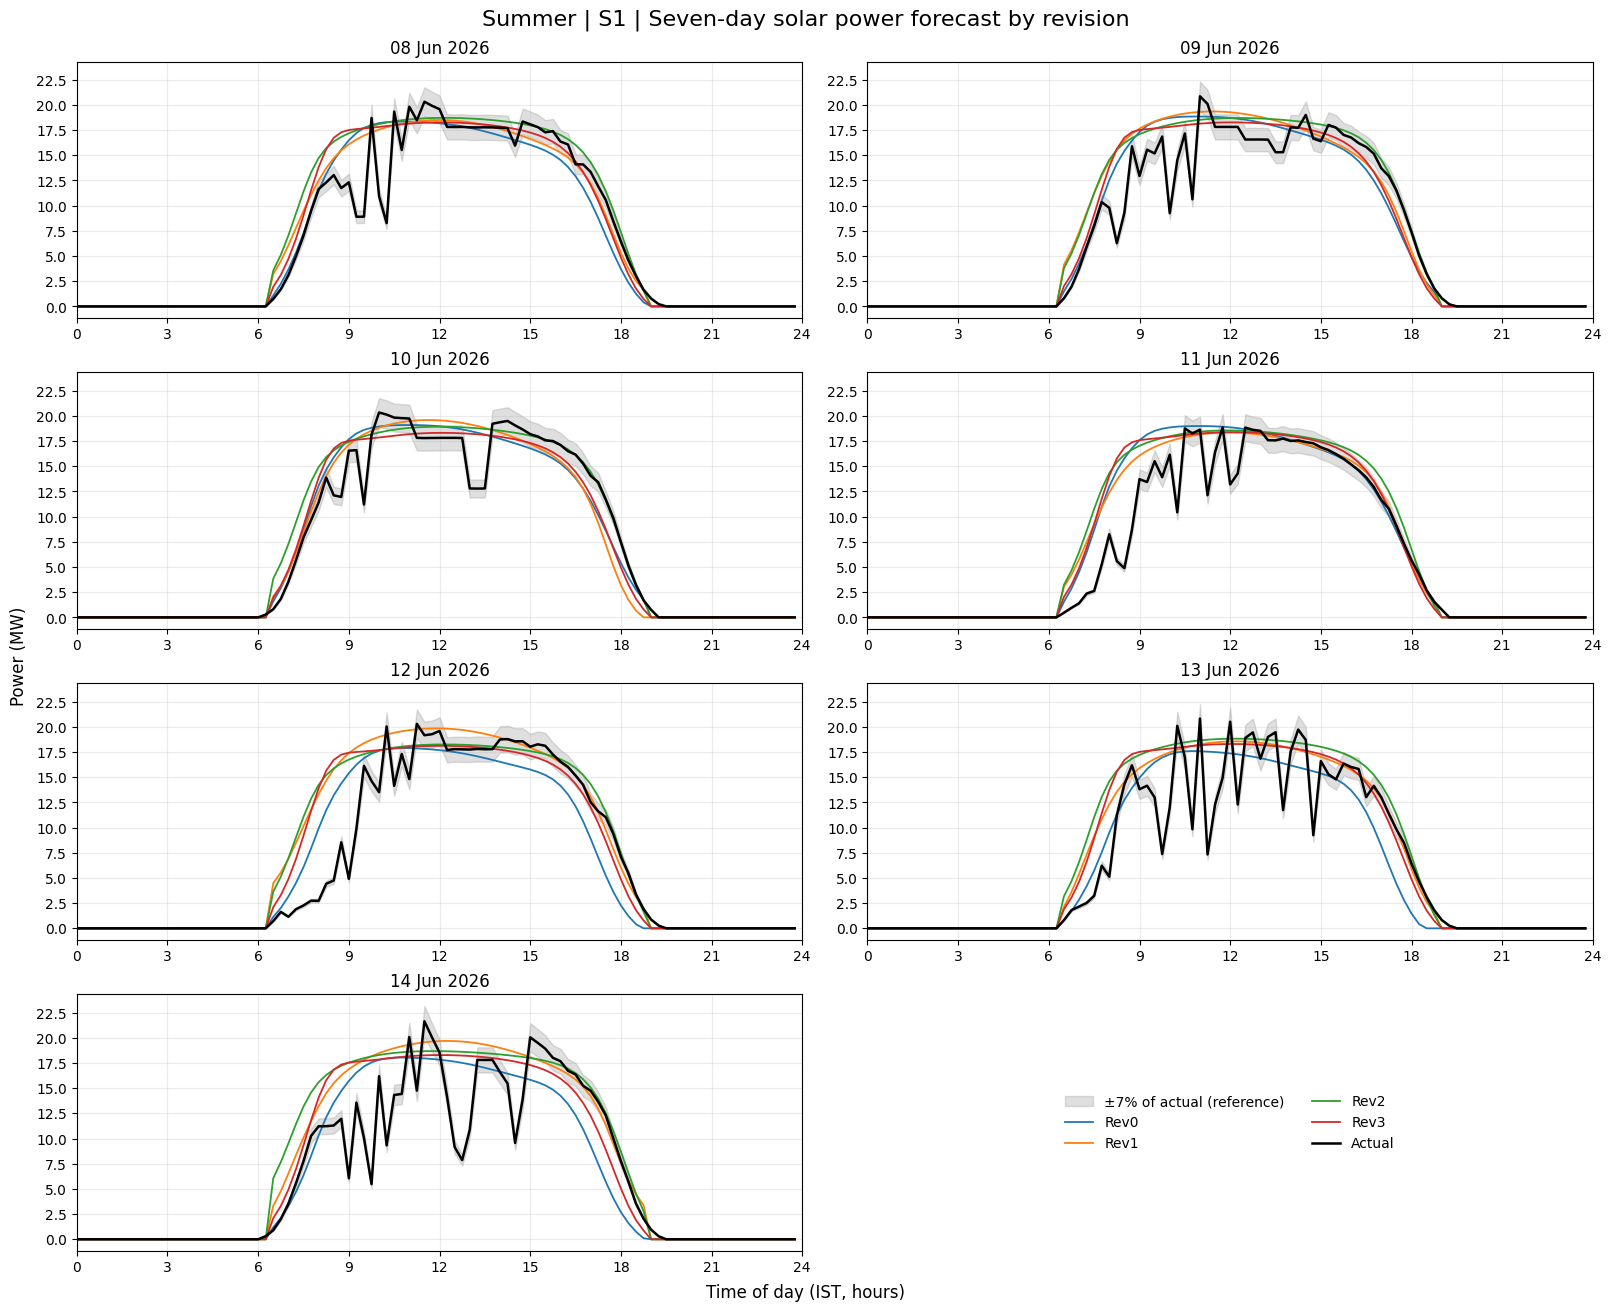

In [21]:
# 7-DAY SUMMER SOLAR POWER FORECAST BY REVISION
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

SEASON = "Summer"
SCENARIO = "S1"

PROJECT_DIR = Path(
    r"C:\Users\yashs\Desktop\ML\Project Fall 2026"
)
results_path = (
    PROJECT_DIR / "Notebooks" / "Results" / SEASON
    / "Predictions" / f"{SEASON}_Daily_RNN_{SCENARIO}.csv"
)

predictions = pd.read_csv(
    results_path, parse_dates=["Target_Time"]
)
test_days = pd.date_range("2026-06-08", "2026-06-14", freq="D")

revision_colors = {
    "Rev0": "tab:blue",
    "Rev1": "tab:orange",
    "Rev2": "tab:green",
    "Rev3": "tab:red",
}

expected_times = pd.date_range(
    test_days[0], periods=7 * 96, freq="15min"
)
expected = pd.MultiIndex.from_product(
    [expected_times, list(revision_colors)],
    names=["Target_Time", "Revision"],
)
observed = pd.MultiIndex.from_frame(
    predictions[["Target_Time", "Revision"]]
)

if not observed.sort_values().equals(expected.sort_values()):
    raise ValueError(
        "Expected exactly four revisions per block for June 8–14."
    )

for column in ("Actual_MW", "Forecast_MW"):
    predictions[column] = pd.to_numeric(
        predictions[column], errors="raise"
    )

if not np.isfinite(
    predictions[["Actual_MW", "Forecast_MW"]].to_numpy()
).all():
    raise ValueError("Missing or infinite actual/forecast values.")

forecasts = predictions.pivot(
    index="Target_Time",
    columns="Revision",
    values="Forecast_MW",
).reindex(index=expected_times, columns=list(revision_colors))

actual_by_revision = predictions.pivot(
    index="Target_Time",
    columns="Revision",
    values="Actual_MW",
).reindex(index=expected_times, columns=list(revision_colors))

if not np.allclose(
    actual_by_revision.to_numpy(),
    actual_by_revision.iloc[:, :1].to_numpy(),
    atol=1e-6,
    rtol=0,
):
    raise ValueError("Actual power differs across revisions.")

actual = actual_by_revision.iloc[:, 0]

fig, axes = plt.subplots(
    4, 2, figsize=(16, 13), layout="constrained"
)
hours = np.arange(96) / 4

for ax, day in zip(axes.flat, test_days):
    day_times = pd.date_range(day, periods=96, freq="15min")
    measured = actual.loc[day_times].to_numpy()

    # Visual reference only; DSM uses installed AC capacity.
    tolerance = 0.07 * np.abs(measured)
    ax.fill_between(
        hours,
        measured - tolerance,
        measured + tolerance,
        color="gray",
        alpha=0.25,
        label="±7% of actual (reference)",
    )

    for revision, color in revision_colors.items():
        ax.plot(
            hours,
            forecasts.loc[day_times, revision].to_numpy(),
            color=color,
            linewidth=1.3,
            label=revision,
        )

    ax.plot(
        hours, measured,
        color="black", linewidth=1.8, label="Actual",
    )

    ax.set_title(day.strftime("%d %b %Y"))
    ax.set_xlim(0, 24)
    ax.set_xticks(np.arange(0, 25, 3))
    ax.yaxis.set_major_locator(MultipleLocator(2.5))
    ax.grid(alpha=0.25)

# Shared scale, retaining any negative measured values.
plot_axes = list(axes.flat)[:7]
lower_limit = min(0.0, min(ax.get_ylim()[0] for ax in plot_axes))
upper_limit = max(ax.get_ylim()[1] for ax in plot_axes)

for ax in plot_axes:
    ax.set_ylim(lower_limit, upper_limit)

legend_ax = axes[3, 1]
legend_ax.axis("off")
handles, labels = axes[0, 0].get_legend_handles_labels()
legend_ax.legend(
    handles, labels, loc="center", ncol=2, frameon=False
)

fig.suptitle(
    f"{SEASON} | {SCENARIO} | Seven-day solar power forecast by revision",
    fontsize=16,
)
fig.supxlabel("Time of day (IST, hours)")
fig.supylabel("Power (MW)")

plt.show()

DSM BAND CALCULATION

DSM band calculated.


# 13. Optional / Experimental Cells

These cells are exploratory demonstrations or duplicate result checks. **DO NOT EXECUTE AUTOMATICALLY.**

In [22]:
import numpy as np
import pandas as pd

# Change to "Scenario 1" in the old notebook.
SCENARIO_NAME = "Scenario 1"

BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1
NUMERICAL_TOLERANCE_MW = 1e-6

actual = np.asarray(y_actual, dtype=np.float64)
predicted = np.asarray(y_pred, dtype=np.float64)

assert actual.shape == predicted.shape
assert actual.ndim == 2 and actual.shape[1] == TARGET_LENGTH
assert np.isfinite(actual).all()
assert np.isfinite(predicted).all()

# Absolute width keeps bounds ordered even for negative measured values.
band_width = BAND_FRACTION * np.abs(actual)
lower_bound = actual - band_width
upper_bound = actual + band_width

inside_band = (
    (predicted >= lower_bound - NUMERICAL_TOLERANCE_MW)
    & (predicted <= upper_bound + NUMERICAL_TOLERANCE_MW)
)

rows = []

groups = {
    "Overall": np.arange(len(actual)),
    **{
        revision: np.asarray(indices, dtype=int)
        for revision, indices in revision_indices_test.items()
    },
}

for revision, indices in groups.items():
    if len(indices) == 0:
        continue

    group_actual = actual[indices]
    group_inside = inside_band[indices]

    for scope, eligible in (
        ("All blocks", np.ones(group_actual.shape, dtype=bool)),
        (
            "Active generation",
            group_actual > ACTIVE_THRESHOLD_MW,
        ),
    ):
        total = int(eligible.sum())
        inside = int((group_inside & eligible).sum())
        outside = total - inside

        rows.append({
            "Scenario": SCENARIO_NAME,
            "Revision": revision,
            "Scope": scope,
            "Evaluated blocks": total,
            "Inside ±7%": inside,
            "Outside ±7%": outside,
            "Inside band %": (
                100.0 * inside / total if total else np.nan
            ),
        })

band_metrics_df = pd.DataFrame(rows)

print(
    band_metrics_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}",
    )
)

  Scenario Revision             Scope  Evaluated blocks  Inside ±7%  Outside ±7%  Inside band %
Scenario 1  Overall        All blocks              2688        1714          974          63.76
Scenario 1  Overall Active generation              1456         482          974          33.10
Scenario 1       R0        All blocks               672         404          268          60.12
Scenario 1       R0 Active generation               364          96          268          26.37
Scenario 1       R1        All blocks               672         422          250          62.80
Scenario 1       R1 Active generation               364         114          250          31.32
Scenario 1       R2        All blocks               672         464          208          69.05
Scenario 1       R2 Active generation               364         156          208          42.86
Scenario 1       R3        All blocks               672         424          248          63.10
Scenario 1       R3 Active generation   